# Credit Risk Prediction Using Machine Learning

**Goal:** predict whether a loan applicant is likely to **default**, using the public *German Credit* dataset (UCI Machine Learning Repository, 1,000 loans), and translate the results into lending decisions.

**Target:** `Default` — `1` = defaulted (bad loan), `0` = no default (good loan).

**Dataset notes (read first)**
- The source file codes the outcome as `credit_risk` (1 = good, 0 = bad). I flip it so that `Default = 1 - credit_risk`, matching the project definition.
- The brief mentions *Income*. **This dataset has no income column**, so I do not invent one. The closest proxies are `savings`, `checking_account`, `employment_length`, `job` and `loan_amount`.
- There are **no missing values** in this file; Phase 2 still checks properly and explains what I would do if there were.

**Notebook map:** 1 Exploratory analysis → 2 Cleaning & preparation → 3 Models → 4 Evaluation → 5 Feature importance → 6 Business interpretation.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")          # so we can import our own models.py
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_validate, cross_val_predict, StratifiedKFold, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler

import models as m   # our reusable code in src/models.py

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {0: "#4C78A8", 1: "#E4572E"}      # blue = no default, red-orange = default
VIS = "../visuals/"

def save(name):
    plt.tight_layout()
    plt.savefig(VIS + name, dpi=150, bbox_inches="tight")

## Phase 1 — Exploratory Data Analysis

In [2]:
df = m.load_data()
print(df.shape)
df.head()

(1000, 21)


,checking_account,duration_months,credit_history,purpose,loan_amount,savings,employment_length,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,Default
0,... < 100 DM,6,critical account/other credits existing,domestic appliances,1169,unknown/no savings account,... >= 7 years,4,male : single,none,...,real estate,67,none,own,2,skilled employee/official,1,yes,yes,0
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,domestic appliances,5951,... < 100 DM,1 <= ... < 4 years,2,female : divorced/separated/married,none,...,real estate,22,none,own,1,skilled employee/official,1,no,yes,1
2,no checking account,12,critical account/other credits existing,retraining,2096,... < 100 DM,4 <= ... < 7 years,2,male : single,none,...,real estate,49,none,own,1,unskilled - resident,2,no,yes,0
3,... < 100 DM,42,existing credits paid back duly till now,radio/television,7882,... < 100 DM,4 <= ... < 7 years,2,male : single,guarantor,...,building society savings agreement/life insurance,45,none,for free,1,skilled employee/official,2,no,yes,0
4,... < 100 DM,24,delay in paying off in the past,car (new),4870,... < 100 DM,1 <= ... < 4 years,3,male : single,none,...,unknown/no property,53,none,for free,2,skilled employee/official,2,no,yes,1


### 1.1 Summary statistics
`describe()` gives mean, std, min, max and quartiles (the 50% row is the median). I add the median explicitly so it is easy to compare with the mean — a large gap signals skew.

In [3]:
num_cols = df.select_dtypes("number").drop(columns="Default").columns.tolist()
summary = df[num_cols].describe().T
summary["median"] = df[num_cols].median()
summary[["mean", "median", "min", "max", "std"]].round(2)

,mean,median,min,max,std
duration_months,20.90,18.0,4.0,72.0,12.06
loan_amount,3271.26,2319.5,250.0,18424.0,2822.74
installment_rate,2.97,3.0,1.0,4.0,1.12
present_residence,2.84,3.0,1.0,4.0,1.10
age,35.55,33.0,19.0,75.0,11.38
number_credits,1.41,1.0,1.0,4.0,0.58
people_liable,1.16,1.0,1.0,2.0,0.36


`loan_amount` has a mean (~3,271) well above its median (~2,320): its distribution is **right-skewed** (a few very large loans). Age is close to symmetric.

### 1.2 Default rate and class balance

         count  percent
Default                
0          700     70.0
1          300     30.0

Default rate = 30.0%  (95% CI: 27.2% to 32.9%)


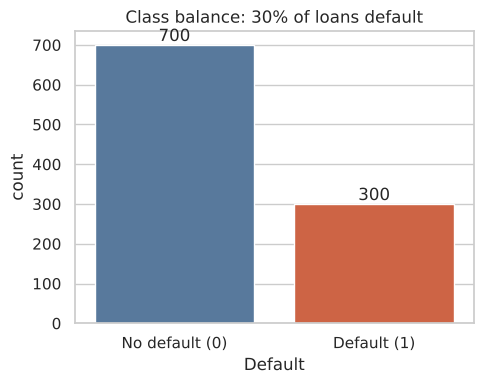

In [4]:
counts = df["Default"].value_counts()
pct = df["Default"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(1)}))

# 95% Wilson confidence interval for the default rate
ci = stats.binomtest(int(counts[1]), len(df)).proportion_ci(method="wilson")
print(f"\nDefault rate = {pct[1]:.1f}%  (95% CI: {ci.low*100:.1f}% to {ci.high*100:.1f}%)")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Default", hue="Default", palette=PALETTE, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
ax.set_xticks([0, 1], ["No default (0)", "Default (1)"])
ax.set_title("Class balance: 30% of loans default")
save("01_default_countplot.png")

**What percentage default?** 30.0% (300 of 1,000; 95% CI roughly 27–33%).

**Is the data balanced?** No — it is a **moderate imbalance (70/30)**. This matters in three ways:
1. A model that predicts "no default" for everyone scores **70% accuracy**, so accuracy alone is misleading. Any model must be judged against this baseline.
2. I use **stratified** train/test splits so both sets keep the 30% rate.
3. I use `class_weight="balanced"` and judge models on **recall, precision, F1 and ROC-AUC**, not accuracy alone.

### 1.3 Age: defaulters vs non-defaulters

         mean  median
Default              
0        36.2    34.0
1        34.0    31.0

Mann-Whitney U test: p = 0.0004
          default_rate_%  count
age_band                       
19-25               42.1    190
26-35               29.6    398
36-50               23.7    299
51+                 27.4    113


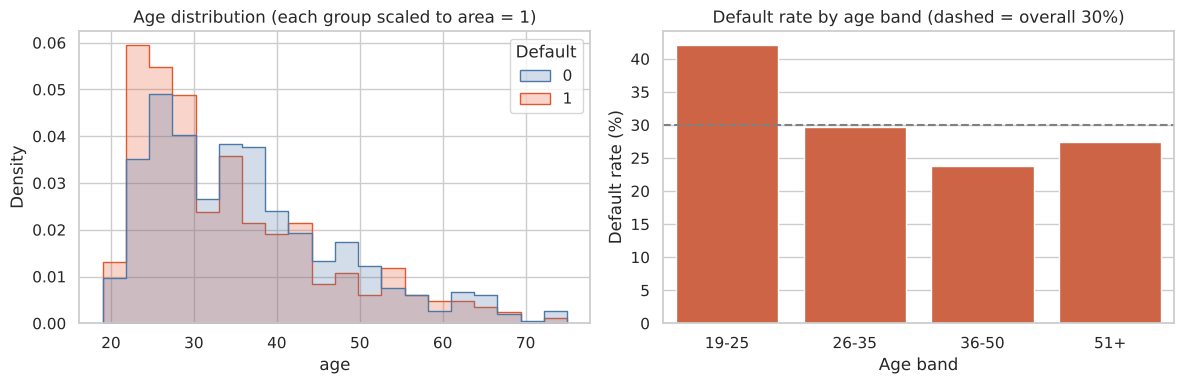

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="age", hue="Default", palette=PALETTE, stat="density",
             common_norm=False, bins=20, element="step", ax=axes[0])
axes[0].set_title("Age distribution (each group scaled to area = 1)")

df["age_band"] = pd.cut(df["age"], [18, 25, 35, 50, 80], labels=["19-25", "26-35", "36-50", "51+"])
rate = df.groupby("age_band", observed=True)["Default"].agg(["mean", "count"])
sns.barplot(x=rate.index, y=rate["mean"]*100, color=PALETTE[1], ax=axes[1])
axes[1].set_ylabel("Default rate (%)"); axes[1].set_xlabel("Age band")
axes[1].axhline(30, ls="--", c="grey"); axes[1].set_title("Default rate by age band (dashed = overall 30%)")
save("02_age_distribution.png")

u = stats.mannwhitneyu(df.loc[df.Default==1, "age"], df.loc[df.Default==0, "age"])
print(df.groupby("Default")["age"].agg(["mean", "median"]).round(1))
print(f"\nMann-Whitney U test: p = {u.pvalue:.4f}")
print(rate.assign(mean=(rate["mean"]*100).round(1)).rename(columns={"mean": "default_rate_%"}))

**Finding:** defaulters are younger (median 31 vs 34). The default rate is **~42% for applicants aged 19–25** against ~24% for ages 36–50. The Mann-Whitney U test (used instead of a t-test because age is not normally distributed) gives p < 0.001, so the age difference is very unlikely to be chance.

*Caution:* this is association, not causation. Age probably stands in for things we cannot see — shorter credit history, lower savings, less stable work.

### 1.4 Loan size vs default

           mean  median
Default                
0        2985.0  2244.0
1        3938.0  2574.0

Mann-Whitney U test: p = 0.0059
             default_rate_%  count
amount_band                       
<1.5k                  28.8    306
1.5-3k                 24.8    314
3-6k                   28.6    231
>6k                    45.6    149


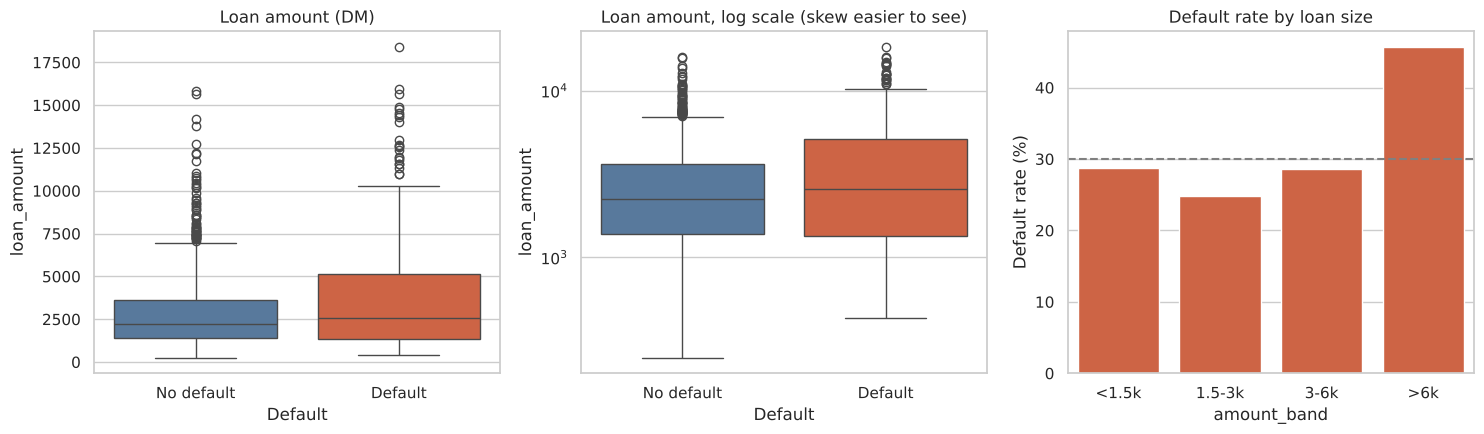

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.boxplot(data=df, x="Default", y="loan_amount", hue="Default", palette=PALETTE, legend=False, ax=axes[0])
axes[0].set_xticks([0, 1], ["No default", "Default"]); axes[0].set_title("Loan amount (DM)")

sns.boxplot(data=df, x="Default", y="loan_amount", hue="Default", palette=PALETTE, legend=False, ax=axes[1])
axes[1].set_yscale("log"); axes[1].set_xticks([0, 1], ["No default", "Default"]); axes[1].set_title("Loan amount, log scale (skew easier to see)")

df["amount_band"] = pd.cut(df["loan_amount"], [0, 1500, 3000, 6000, 20000],
                           labels=["<1.5k", "1.5-3k", "3-6k", ">6k"])
rate = df.groupby("amount_band", observed=True)["Default"].agg(["mean", "count"])
sns.barplot(x=rate.index, y=rate["mean"]*100, color=PALETTE[1], ax=axes[2])
axes[2].axhline(30, ls="--", c="grey"); axes[2].set_ylabel("Default rate (%)")
axes[2].set_title("Default rate by loan size")
save("03_loan_amount_boxplots.png")

u = stats.mannwhitneyu(df.loc[df.Default==1, "loan_amount"], df.loc[df.Default==0, "loan_amount"])
print(df.groupby("Default")["loan_amount"].agg(["mean", "median"]).round(0))
print(f"\nMann-Whitney U test: p = {u.pvalue:.4f}")
print((rate.assign(mean=(rate["mean"]*100).round(1))).rename(columns={"mean": "default_rate_%"}))

**Finding:** the relationship is **not linear**. Default rates are roughly flat (25–29%) up to 6,000 DM, then jump to **~46% for loans above 6,000 DM**. The median difference between groups is modest (2,575 vs 2,244 DM) but significant (p ≈ 0.006); the boxplots show defaulters have a longer upper tail of large loans. This is a good reason to try tree-based models, which capture thresholds like this. Loan *duration* is an even stronger signal (see the heatmap).

Outliers: large loans are genuine, not errors, so I **keep** them rather than delete real high-risk cases.

### 1.5 Which categorical variables relate to default?
For each category I plot the default rate, and test association with a **chi-square test**. Because a p-value only says *whether* an association exists, I also report **Cramér's V** (0 = none, 1 = perfect) to show *how strong* it is.

,variable,chi2_p_value,cramers_V
0,checking_account,0.0000,0.3517
1,credit_history,0.0000,0.2484
2,savings,0.0000,0.1900
3,employment_length,0.0010,0.1355
4,housing,0.0001,0.1349


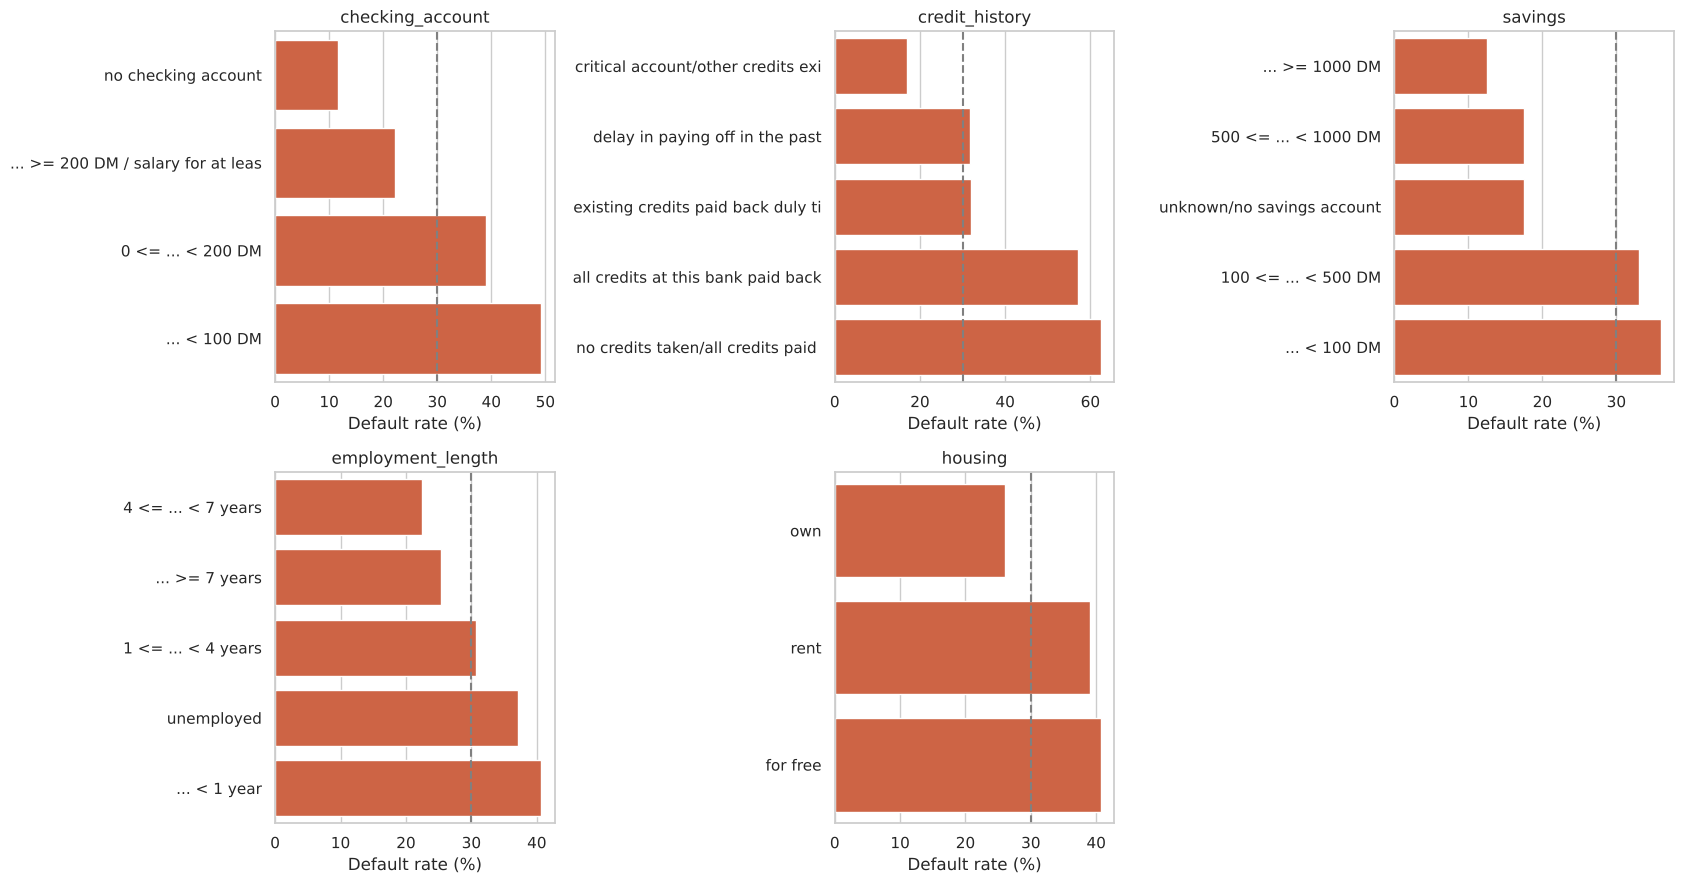

In [7]:
cats = ["checking_account", "credit_history", "savings", "employment_length", "housing"]

def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(t)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))

rows = []
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.flat, cats):
    r = (df.groupby(c)["Default"].mean() * 100).sort_values()
    sns.barplot(x=r.values, y=[s[:34] for s in r.index], color=PALETTE[1], ax=ax)
    ax.axvline(30, ls="--", c="grey"); ax.set_title(c); ax.set_xlabel("Default rate (%)"); ax.set_ylabel("")
    p = stats.chi2_contingency(pd.crosstab(df[c], df["Default"]))[1]
    rows.append({"variable": c, "chi2_p_value": p, "cramers_V": cramers_v(df[c], df["Default"])})
axes.flat[-1].axis("off")
save("04_default_rate_by_category.png")
pd.DataFrame(rows).sort_values("cramers_V", ascending=False).round(4)

**Findings** (all p < 0.01 — these associations are statistically significant):
- **Checking account** is the strongest: **49% default** with balance < 100 DM versus **12%** with no checking account.
- **Credit history:** applicants flagged "critical account / other credits" default *less* (17%) than those with a clean-looking record (~32–62%). This is counter-intuitive. One possible explanation (a hypothesis I have not tested) is that such customers were screened more strictly before being approved. It is a good example of why you must not read model output as causal.
- **Savings:** < 100 DM → 36% default; ≥ 1,000 DM → 12%.
- **Employment:** < 1 year → 41% default; 4–7 years → 22%.
- **Housing:** renters (39%) and those living "for free" (41%) default more than owners (26%).

### 1.6 Correlation matrix

duration_months      0.215
loan_amount          0.155
age                 -0.091
installment_rate     0.072
number_credits      -0.046
people_liable       -0.003
present_residence    0.003
Name: Default, dtype: float64

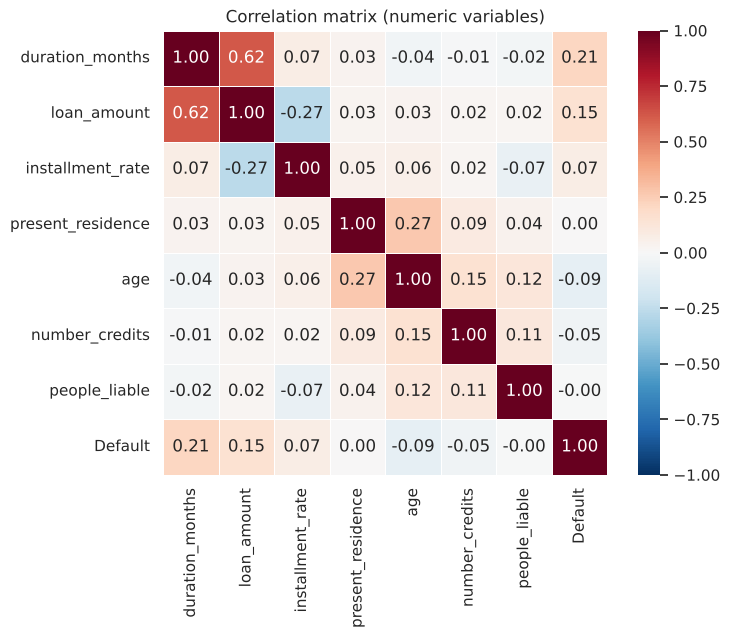

In [8]:
corr_df = df[num_cols + ["Default"]].corr()      # Pearson; with a 0/1 target this is the point-biserial correlation
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=.5, ax=ax)
ax.set_title("Correlation matrix (numeric variables)")
save("05_correlation_heatmap.png")
corr_df["Default"].drop("Default").sort_values(key=abs, ascending=False).round(3)

**Findings**
- Strongest correlates of `Default`: **loan duration (+0.21)**, **loan amount (+0.15)** and **age (−0.09)**. All are weak-to-moderate: no single numeric variable predicts default well alone.
- **Duration and loan amount are correlated (~0.62)** — bigger loans run longer. This is **multicollinearity**: it makes individual logistic-regression coefficients less stable to interpret (the *predictions* are still fine).
- Correlation only captures *linear* relationships between numeric variables, so it misses the categorical effects (checking account, savings) and the non-linear loan-size effect found above.

## Phase 2 — Data Cleaning & Preparation

In [9]:
clean = df.drop(columns=["age_band", "amount_band"])   # drop helper columns used for plotting
missing = clean.isnull().sum()
print("Total missing values:", missing.sum())
print(missing[missing > 0] if missing.sum() else "No column has missing values.")
print("Duplicate rows:", df.duplicated().sum())
print("Age range:", df.age.min(), "-", df.age.max(), "| Loan amount range:", df.loan_amount.min(), "-", df.loan_amount.max())

Total missing values: 0
No column has missing values.
Duplicate rows: 0
Age range: 19 - 75 | Loan amount range: 250 - 18424


**Missing values:** none, and no duplicates or impossible values (ages 19–75, positive amounts). I checked rather than assumed.

If values *were* missing, my approach would be: numeric → impute the **median** (robust to the skew seen above); categorical → impute the **most frequent** value or add an explicit "unknown" category; and always fit the imputer on the **training set only**. Imputation would sit inside the pipeline below for the same leakage reason as scaling.

(Note: `savings = "unknown/no savings account"` looks like missing data but is a real category in the dataset's documentation, so I keep it as its own level.)

### 2.1 Encoding categorical variables
`pd.get_dummies()` converts each category to 0/1 columns. `drop_first=True` removes one level per variable to avoid perfect collinearity (the 'dummy variable trap').

In [10]:
X = df.drop(columns=["Default", "age_band", "amount_band"])
y = df["Default"]

demo = pd.get_dummies(X, drop_first=True)
print(f"{X.shape[1]} original columns -> {demo.shape[1]} columns after get_dummies")
demo.filter(like="housing").head()

20 original columns -> 48 columns after get_dummies


,housing_own,housing_rent
0,True,False
1,True,False
2,True,False
3,False,False
4,False,False


### 2.2 Feature scaling and avoiding data leakage
Logistic regression is sensitive to feature scale (e.g. `loan_amount` in thousands vs `installment_rate` of 1–4), so I use `StandardScaler` (mean 0, std 1).

**Important:** the scaler must learn its mean/std from the **training data only**. If I scaled the whole dataset first, information from the test set would leak into training and inflate results. So scaling and encoding sit **inside a scikit-learn `Pipeline`** (see `src/models.py`) and are fitted on training data only. The pipeline uses `OneHotEncoder`, which does the same job as `get_dummies` but remembers the training categories, so it is safe on new data.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=m.RANDOM_STATE)
print(f"Train: {len(X_train)} rows, default rate {y_train.mean():.1%} | Test: {len(X_test)} rows, default rate {y_test.mean():.1%}")

# Demonstrate StandardScaler: fit on train, apply to both
sc = StandardScaler().fit(X_train[num_cols])
print("\nScaled TRAIN means (should be ~0):", sc.transform(X_train[num_cols]).mean(axis=0).round(3))
print("Scaled TEST  means (not exactly 0 - and that is correct):", sc.transform(X_test[num_cols]).mean(axis=0).round(2))

Train: 800 rows, default rate 30.0% | Test: 200 rows, default rate 30.0%

Scaled TRAIN means (should be ~0): [ 0.  0. -0. -0.  0.  0.  0.]
Scaled TEST  means (not exactly 0 - and that is correct): [ 0.06  0.15  0.14  0.07  0.1  -0.   -0.07]


## Phase 3 — Machine Learning Models

| Model | Purpose |
|---|---|
| **Logistic Regression** | Interpretable linear baseline |
| **Decision Tree** | Captures non-linear thresholds and interactions; easy to explain as rules |
| **Random Forest** | Averages many trees to reduce a single tree's tendency to overfit |

Each model's hyperparameters are tuned with **5-fold stratified cross-validation on the training set only**, optimising **F1** (balances catching defaulters against false alarms). The test set stays untouched until Phase 4.

In [12]:
spec = m.build_models(X)
fitted, best = {}, {}
for name, (pipe, grid) in spec.items():
    search = m.tune(pipe, grid, X_train, y_train, scoring="f1")
    fitted[name] = search.best_estimator_
    best[name] = search.best_params_
    print(f"{name:20s} CV F1 = {search.best_score_:.3f}   best params: {search.best_params_}")

Logistic Regression  CV F1 = 0.602   best params: {'clf__C': 0.1}


Decision Tree        CV F1 = 0.558   best params: {'clf__max_depth': 5, 'clf__min_samples_leaf': 5}


Random Forest        CV F1 = 0.619   best params: {'clf__max_depth': None, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}


## Phase 4 — Evaluation

Terminology (the **positive class is Default = 1**):
- **True Positive (TP):** predicted default, actually defaulted → risk correctly caught.
- **False Positive (FP):** predicted default, actually repaid → a good customer wrongly declined (lost business).
- **False Negative (FN):** predicted repay, actually defaulted → a bad loan approved (credit loss). *Usually the costliest error.*
- **True Negative (TN):** predicted repay, actually repaid.

**Precision** = TP/(TP+FP) — of those flagged, how many really default. **Recall** = TP/(TP+FN) — of all real defaulters, how many we catch. **F1** = harmonic mean of the two.

In [13]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
rows = {"Baseline: approve everyone": m.evaluate(baseline, X_test, y_test)}
for name, mod in fitted.items():
    rows[name] = m.evaluate(mod, X_test, y_test)

results = pd.DataFrame(rows).T
display_tbl = (results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]] * 100).round(1)
display_tbl.columns = ["Accuracy %", "Precision %", "Recall %", "F1 %", "ROC-AUC (x100)"]
display_tbl

,Accuracy %,Precision %,Recall %,F1 %,ROC-AUC (x100)
Baseline: approve everyone,70.0,0.0,0.0,0.0,50.0
Logistic Regression,73.0,53.4,78.3,63.5,81.0
Decision Tree,56.0,37.3,68.3,48.2,59.8
Random Forest,71.0,51.2,71.7,59.7,79.1


The **baseline row** (predict 'no default' for everyone) shows what accuracy you get for free: 70%. Precision/recall are 0 because it never flags anyone. Any real model must be read against this.

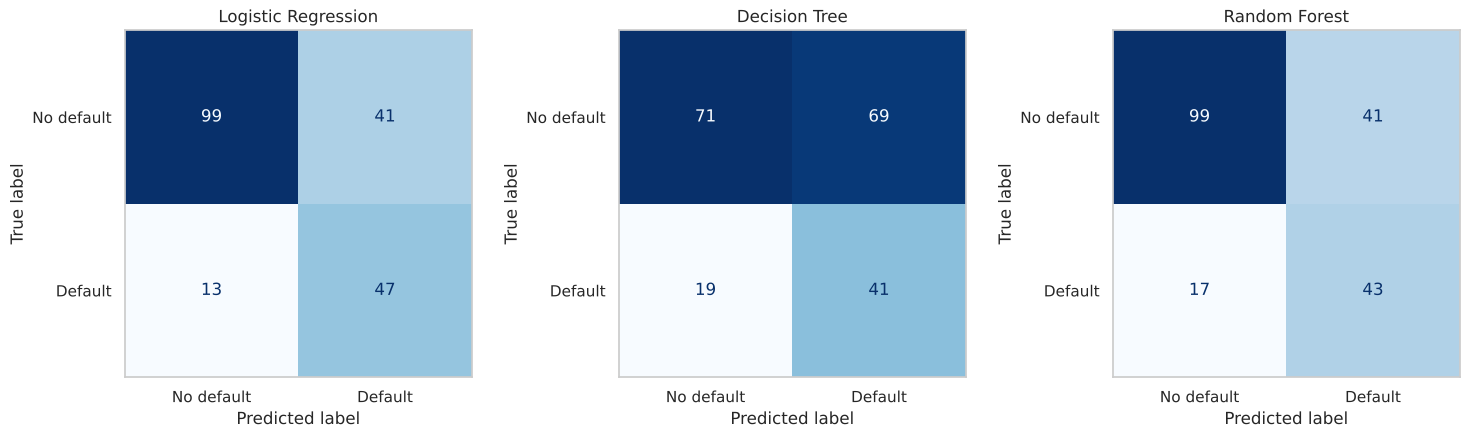

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, mod) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(
        mod, X_test, y_test, display_labels=["No default", "Default"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name); ax.grid(False)
save("06_confusion_matrices.png")

In [15]:
for name, mod in fitted.items():
    tn, fp, fn, tp = confusion_matrix(y_test, mod.predict(X_test)).ravel()
    print(f"{name}\n  TP={tp}: defaulters correctly flagged | FN={fn}: defaulters MISSED (bad loans approved)"
          f"\n  FP={fp}: good customers wrongly declined | TN={tn}: good customers correctly approved\n")

Logistic Regression
  TP=47: defaulters correctly flagged | FN=13: defaulters MISSED (bad loans approved)
  FP=41: good customers wrongly declined | TN=99: good customers correctly approved

Decision Tree
  TP=41: defaulters correctly flagged | FN=19: defaulters MISSED (bad loans approved)
  FP=69: good customers wrongly declined | TN=71: good customers correctly approved

Random Forest
  TP=43: defaulters correctly flagged | FN=17: defaulters MISSED (bad loans approved)
  FP=41: good customers wrongly declined | TN=99: good customers correctly approved



### 4.1 A fairer comparison: nested cross-validation
A single 200-row test set contains only 60 defaulters, so its metrics are noisy (one or two customers moves recall by ~2 points). To compare models more reliably I use **nested 5-fold CV**: the hyperparameter search runs *inside* each training fold, and every observation is used for testing exactly once.

In [16]:
outer = StratifiedKFold(5, shuffle=True, random_state=7)
inner_cv = StratifiedKFold(5, shuffle=True, random_state=m.RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

cv_rows = {}
for name, (pipe, grid) in spec.items():
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=inner_cv, n_jobs=-1)
    s = cross_validate(gs, X, y, cv=outer, scoring=scoring)
    cv_rows[name] = {k: (s[f"test_{k}"].mean(), s[f"test_{k}"].std()) for k in scoring}

cv_tbl = pd.DataFrame({n: {k: f"{v[0]*100:.1f} ± {v[1]*100:.1f}" for k, v in r.items()} for n, r in cv_rows.items()}).T
cv_tbl.columns = ["Accuracy %", "Precision %", "Recall %", "F1 %", "ROC-AUC (x100)"]
cv_tbl

,Accuracy %,Precision %,Recall %,F1 %,ROC-AUC (x100)
Logistic Regression,72.4 ± 2.9,53.2 ± 3.8,71.3 ± 3.9,60.9 ± 3.0,78.5 ± 2.7
Decision Tree,62.1 ± 5.4,43.3 ± 4.7,75.3 ± 9.5,54.4 ± 3.0,69.4 ± 2.7
Random Forest,73.1 ± 1.2,54.0 ± 1.6,70.0 ± 3.2,60.9 ± 1.7,79.6 ± 2.2


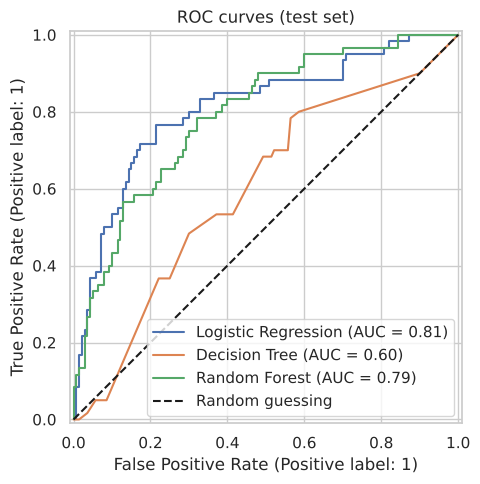

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for name, mod in fitted.items():
    RocCurveDisplay.from_estimator(mod, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guessing"); ax.legend(loc="lower right")
ax.set_title("ROC curves (test set)")
save("07_roc_curves.png")

### Interpreting the results

**Test-set results (200 applicants, 60 defaulters):**

| | TP | FN | FP | TN |
|---|---|---|---|---|
| Logistic Regression | 47 | 13 | 41 | 99 |
| Decision Tree | 41 | 19 | 69 | 71 |
| Random Forest | 43 | 17 | 41 | 99 |

- **Logistic Regression** caught 47 of 60 defaulters (recall 78%) but wrongly declined 41 good customers (precision 53%, i.e. roughly half its "default" flags are false alarms).
- **Random Forest** caught 43 of 60 (recall 72%) with the same 41 false alarms.
- **Decision Tree** is clearly the weakest: 69 false positives and only 56% accuracy, *below* the 70% do-nothing baseline. A single tree, even pruned, fits noise in 800 rows.

**Which model is best? The honest answer is "Logistic Regression and Random Forest are tied."**
- On the single test split, Logistic Regression looks slightly better (F1 63.5 vs 59.7).
- In nested cross-validation, which uses all 1,000 loans and is more trustworthy, they are indistinguishable: F1 60.9% for both, ROC-AUC 78.5 ± 2.7 vs 79.6 ± 2.2. The gap is smaller than one standard deviation, so I cannot claim either is better. Random Forest is slightly more *stable* (lower spread across folds).
- I therefore do **not** claim that Random Forest wins. It plausibly doesn't beat the linear model here because the dataset is small (1,000 rows) and its signal is mostly additive effects of categorical variables, which logistic regression models well. Forests tend to pull ahead with more data and more complex interactions.

**Accuracy needs context.** 71–73% accuracy sounds modest and is only 1–3 points above the 70% baseline. The real value is in *ranking* risk: ROC-AUC of ~0.79 means that, picking one defaulter and one non-defaulter at random, the model gives the defaulter the higher risk score about 79% of the time (50% = guessing). I have not benchmarked against the published literature, but these are moderate numbers rather than suspiciously high ones, which is what I would expect from a small, noisy credit dataset.

## Phase 5 — Feature Importance (Random Forest)

`feature_importances_` measures how much each feature reduces impurity across all trees. Because one-hot encoding splits a variable like `savings` into several dummy columns, I show both the individual columns and the **summed importance per original variable**.

checking_account           0.223
duration_months            0.095
loan_amount                0.083
savings                    0.070
credit_history             0.067
age                        0.060
property                   0.057
employment_length          0.056
purpose                    0.053
other_installment_plans    0.042
dtype: float64

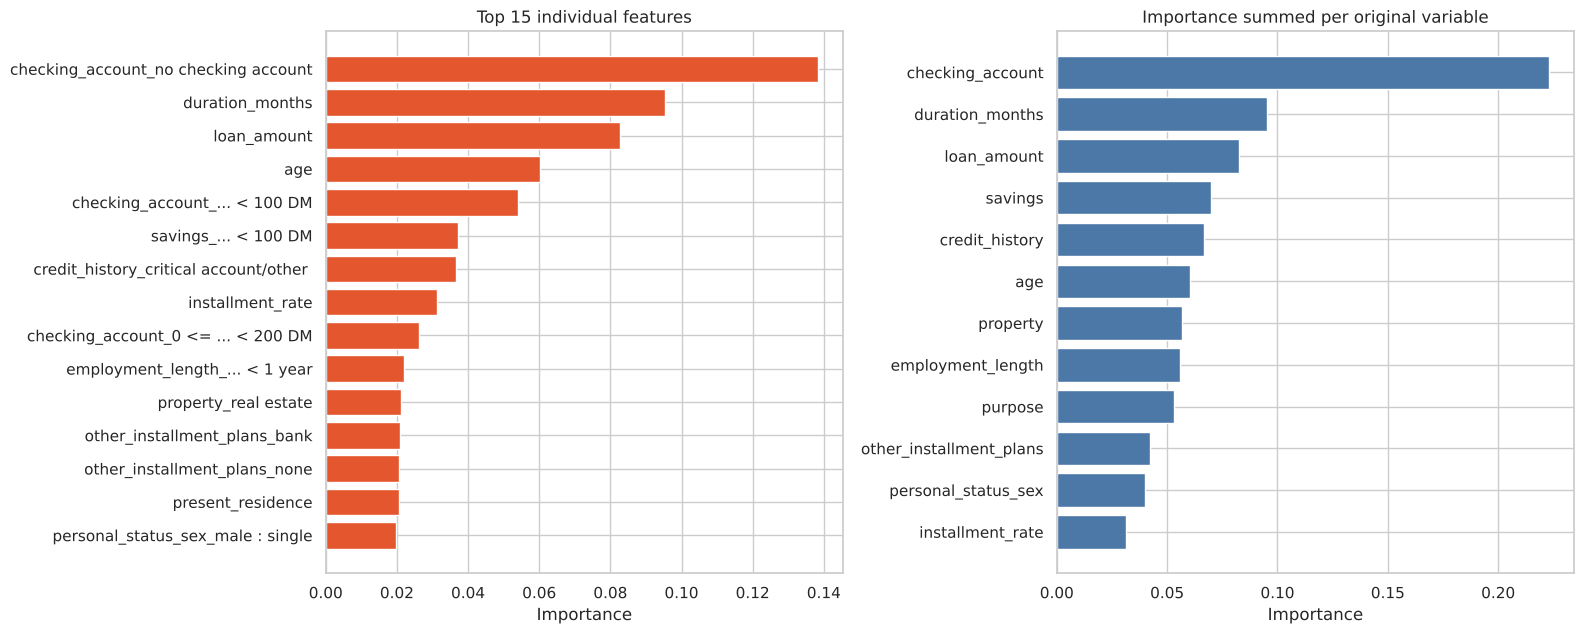

In [18]:
rf = fitted["Random Forest"]
names = m.feature_names(rf)
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
grouped = m.group_importance(names, rf.named_steps["clf"].feature_importances_, X.columns.tolist())

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
top = imp.head(15)[::-1]
axes[0].barh([s[:38] for s in top.index], top.values, color=PALETTE[1])
axes[0].set_title("Top 15 individual features"); axes[0].set_xlabel("Importance")
g = grouped.head(12)[::-1]
axes[1].barh(g.index, g.values, color=PALETTE[0])
axes[1].set_title("Importance summed per original variable"); axes[1].set_xlabel("Importance")
save("08_rf_feature_importance.png")
grouped.head(10).round(3)

**Why impurity importance can mislead:** it is biased towards numeric variables with many distinct values (`loan_amount`, `age`) because they offer many possible split points. So I cross-check with **permutation importance** on the held-out test set: shuffle one variable and measure how much the model's AUC drops.

checking_account    0.138
duration_months     0.016
loan_amount         0.015
credit_history      0.015
savings             0.012
purpose             0.012
age                 0.008
other_debtors       0.007
dtype: float64

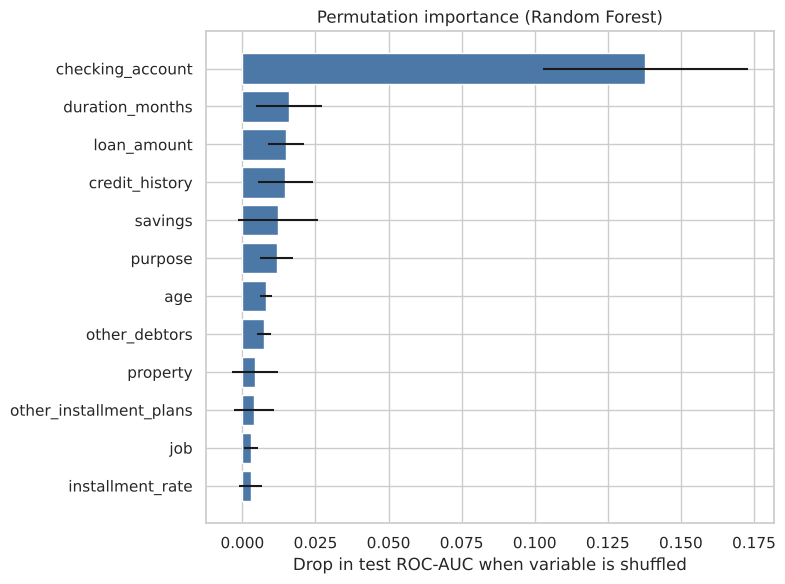

In [19]:
pi = permutation_importance(rf, X_test, y_test, scoring="roc_auc", n_repeats=30,
                            random_state=m.RANDOM_STATE, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
perm_sd = pd.Series(pi.importances_std, index=X.columns)[perm.index]

fig, ax = plt.subplots(figsize=(8, 6))
p = perm.head(12)[::-1]
ax.barh(p.index, p.values, xerr=perm_sd[p.index].values, color=PALETTE[0])
ax.set_xlabel("Drop in test ROC-AUC when variable is shuffled"); ax.set_title("Permutation importance (Random Forest)")
save("09_permutation_importance.png")
perm.head(8).round(3)

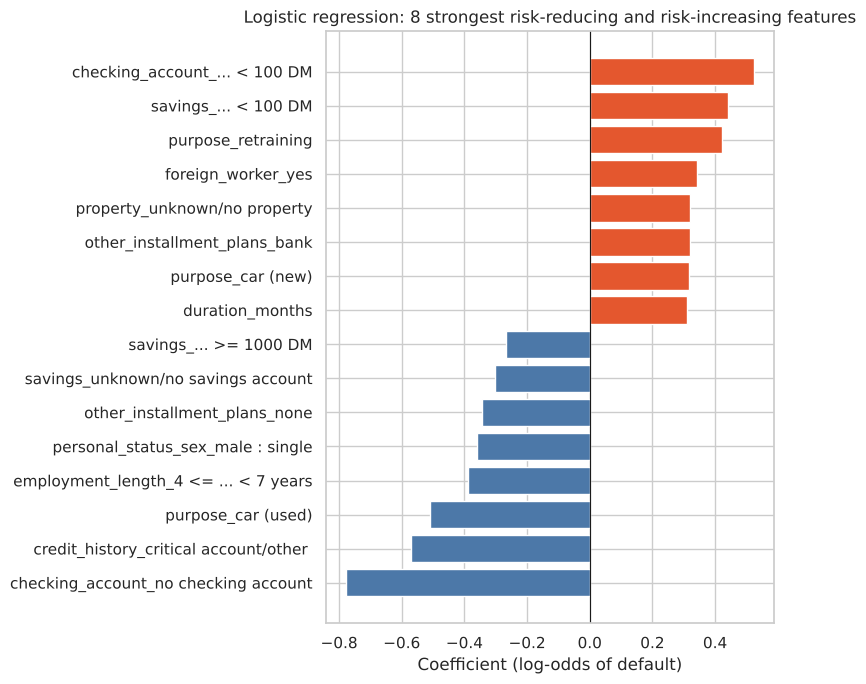

In [20]:
# Cross-check against the interpretable model: logistic regression coefficients (on standardised inputs)
lr = fitted["Logistic Regression"]
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=m.feature_names(lr)).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
show = pd.concat([coef.head(8), coef.tail(8)])
ax.barh([s[:38] for s in show.index], show.values, color=[PALETTE[0] if v < 0 else PALETTE[1] for v in show.values])
ax.axvline(0, c="k", lw=.8); ax.set_xlabel("Coefficient (log-odds of default)")
ax.set_title("Logistic regression: 8 strongest risk-reducing and risk-increasing features")
save("10_logreg_coefficients.png")

### Interpreting feature importance

Both methods agree on the top of the ranking:

1. **`checking_account` is by far the most important variable** (22% of impurity importance; and shuffling it drops test AUC by ~0.14, about nine times more than the next variable). Customers with low balances default far more often (49% vs 12% for no account), and the balance is a direct, recent signal of financial health.
2. **`duration_months` and `loan_amount`** come next. Longer and larger loans mean more time and more money exposed to something going wrong, and above ~6,000 DM the default rate jumps (Phase 1).
3. **`savings` and `credit_history`** follow: savings are a buffer against missed payments, and past repayment behaviour is the classic predictor of future behaviour.
4. **`age`** is moderately important (younger applicants default more).

**A correction to my own expectations:** I expected employment length to be important. Its impurity importance is mid-table (~5.6%) and its permutation importance is close to zero: once checking account, savings and loan size are known, employment length adds little extra. It is related to default on its own (chi-square p = 0.001) but largely redundant with the other variables.

**Caveats:** importance shows what the model *uses*, not what *causes* default. Variables are correlated (loan amount and duration, r = 0.62), which splits importance between them. The logistic-regression coefficients tell the same story in direction, which gives extra confidence.

## Phase 6 — Business Interpretation

### 6.1 Turning predictions into decisions: the cost of errors
In lending the two mistakes are **not equally costly**. The original German Credit documentation assigns a bad loan approved (FN) a cost **5× higher** than a good customer rejected (FP). I use that ratio as an *illustrative assumption* (real costs depend on loan size, margin and recovery rates).

The default decision threshold of 0.5 is therefore not necessarily right. I pick the cost-minimising threshold using **out-of-fold predictions on the training set only**, then test it once on the held-out test set.

Reference: reject everyone would cost 140


,model,rule,recall %,precision %,bad loans missed (FN),good customers declined (FP),total cost
0,Logistic Regression,threshold 0.50,78.3,53.4,13,41,106
1,Logistic Regression,tuned threshold 0.30,88.3,39.6,7,81,116
2,Random Forest,threshold 0.50,71.7,51.2,17,41,126
3,Random Forest,tuned threshold 0.30,95.0,39.3,3,88,103
4,(no model),approve everyone,0.0,NaN,60,0,300


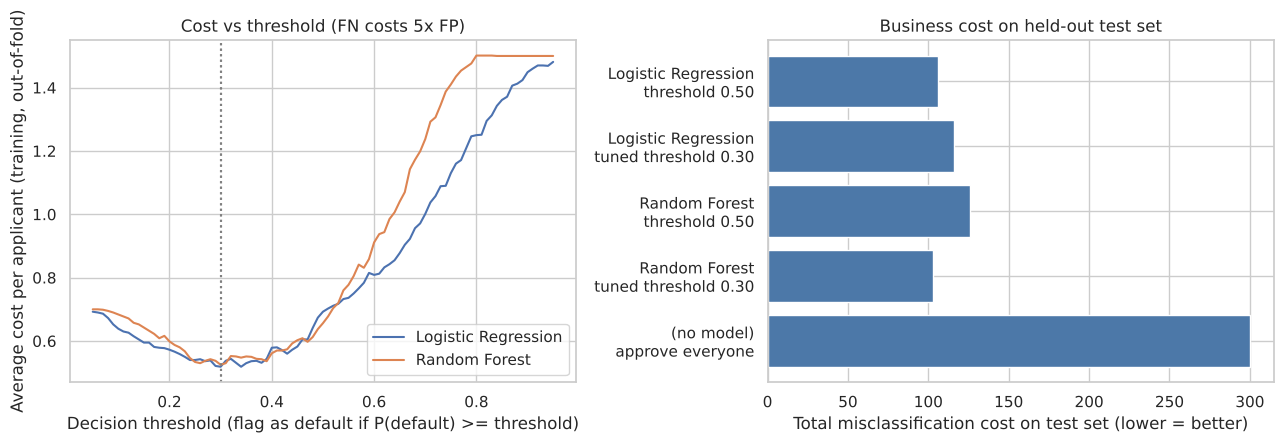

In [21]:
FN_COST, FP_COST = 5, 1
cands = {n: fitted[n] for n in ["Logistic Regression", "Random Forest"]}

thresholds = np.arange(0.05, 0.96, 0.01)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
summary = []
for name, mod in cands.items():
    oof = cross_val_predict(mod, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=1),
                            method="predict_proba")[:, 1]
    costs = [m.expected_cost(y_train, (oof >= t).astype(int), FN_COST, FP_COST) for t in thresholds]
    t_best = thresholds[int(np.argmin(costs))]
    axes[0].plot(thresholds, np.array(costs) / len(y_train), label=name)
    axes[0].axvline(t_best, ls=":", c="grey")
    proba = mod.predict_proba(X_test)[:, 1]
    for label, t in [("threshold 0.50", 0.5), (f"tuned threshold {t_best:.2f}", t_best)]:
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        summary.append({"model": name, "rule": label, "recall %": round(100*tp/(tp+fn), 1),
                        "precision %": round(100*tp/(tp+fp), 1), "bad loans missed (FN)": fn,
                        "good customers declined (FP)": fp, "total cost": m.expected_cost(y_test, pred, FN_COST, FP_COST)})
axes[0].set_xlabel("Decision threshold (flag as default if P(default) >= threshold)")
axes[0].set_ylabel("Average cost per applicant (training, out-of-fold)")
axes[0].set_title("Cost vs threshold (FN costs 5x FP)"); axes[0].legend()

approve_all = m.expected_cost(y_test, np.zeros(len(y_test), int), FN_COST, FP_COST)
reject_all = m.expected_cost(y_test, np.ones(len(y_test), int), FN_COST, FP_COST)
summary.append({"model": "(no model)", "rule": "approve everyone", "recall %": 0.0, "precision %": np.nan,
                "bad loans missed (FN)": int(y_test.sum()), "good customers declined (FP)": 0, "total cost": approve_all})
summary = pd.DataFrame(summary)
bars = summary.set_index(summary["model"] + "\n" + summary["rule"])["total cost"]
axes[1].barh(bars.index[::-1], bars.values[::-1], color=PALETTE[0])
axes[1].set_xlabel("Total misclassification cost on test set (lower = better)")
axes[1].set_title("Business cost on held-out test set")
save("11_cost_analysis.png")
print(f"Reference: reject everyone would cost {reject_all}")
summary

### 6.2 What the cost analysis shows
- With a 5:1 cost ratio, **any of these models is far better than approving everyone**: total cost drops from 300 to about 103–126 (a 58–66% reduction) on the test set.
- Lowering the threshold to 0.30 trades more declined good customers (FP up from ~41 to 81–88) for far fewer missed defaulters (FN down to 3–7). It helped Random Forest (cost 126 → 103) but *not* Logistic Regression (106 → 116). **That inconsistency is itself a finding:** with only 60 defaulters in the test set, differences of 10–20 cost points are within noise. The robust conclusion is that the threshold should be a *business policy decision*, set from real cost data and risk appetite, not a number to optimise on 200 rows.
- A sobering reference point: simply **rejecting everyone** would cost 140. Under a 5:1 ratio and a 30% default rate, the best model beats that by only ~25%. The model is useful but not a magic filter.

### 6.3 Key findings
- About **30%** of loans in the data default; applicants with **low checking balances, long/large loans, little savings, short employment or youth** are markedly higher risk, and these differences are statistically significant.
- **Logistic Regression and Random Forest perform equivalently** (~73% accuracy, ~61% F1, ROC-AUC ~0.79) and both clearly beat a single Decision Tree (AUC ~0.69) and the approve-everyone baseline. The models rank risk well but a meaningful share of flags are false alarms (precision ~53%).
- **Checking account status** is the dominant predictor.

### 6.4 Business impact
A well-calibrated model like this can:
- **Reduce loan losses** by flagging high-risk applicants for review or tighter terms (e.g. lower limit, guarantor, higher price). In the cost analysis it cut illustrative losses by well over half versus no screening.
- **Improve lending decisions** by giving underwriters a consistent, data-driven risk score to complement their judgement, rather than replacing it.
- **Support responsible lending** by steering at-risk customers away from credit they may not be able to afford, and by setting the threshold to balance losses against turning away good customers.
- **Improve customer outcomes** by reducing unaffordable borrowing and the distress that comes with default.

Practical deployment: use the model as a **referral tool** (high score = manual review), not an automatic decline, given that about half of flagged customers would have repaid.

### 6.5 Limitations
- **Small dataset:** 1,000 loans, only 300 defaults and 60 in the test set. Metrics carry real uncertainty (note the ± in the CV table), and I cannot reliably separate the top two models.
- **Old, historical data:** collected decades ago (the dataset was donated to UCI in 1994). Economic conditions, products and customer behaviour have changed; the model would need retraining on current data.
- **Missing information:** no income, and no repayment-to-income ratio, which a real lender would use.
- **Historical bias and fairness:** the data contains `personal_status_sex`, `age` and `foreign_worker`. Using protected characteristics in lending raises legal and ethical issues (UK Equality Act, FCA Consumer Duty). The age effect found here could disadvantage young applicants for reasons unrelated to their individual behaviour. A real system would test for disparate impact and likely exclude such features. Also, the data only contains customers who were *approved* in the past, so it cannot show how rejected applicants would have behaved (selection bias).
- **Explainability:** the Random Forest is harder to explain than logistic regression. Lenders must be able to give reasons for decisions. Since the two perform similarly here, the more interpretable logistic regression is arguably the better practical choice.
- **Association, not causation**, as seen with the counter-intuitive credit-history result.
- **Assumed costs:** the 5:1 ratio is from the dataset documentation, not from a real lender.

### 6.6 Future improvements
- **Gradient boosting (XGBoost / LightGBM)**, often the strongest on tabular credit data; compare using the same nested-CV protocol.
- **More customer features** (income, debt-to-income, transaction behaviour) and **larger datasets** to give non-linear models room to outperform.
- **Probability calibration** and **SHAP values** for per-customer explanations.
- **Fairness audit** across age and gender groups.
- **Real-time prediction:** wrap the pipeline in an API, monitor for data drift, and retrain regularly.